# 01 — Data Exploration (EDA)

**Dataset:** `dataset/SMAH-CTI.csv`
**Feeds thesis section:** Chapter 4.1 — Exploratory Data Analysis

All figures are saved to `artifacts/figs/` and summary statistics are written to
`artifacts/eda_summary.json`. The notebook tolerates the SMAH-CTI schema, where
`doc_id` is the document key and `relevant` is stored as `yes`/`no`.

**Revision notes (post-review):**
- Paths resolved via `PROJECT_ROOT` (no `../` relative paths).
- `raw_rows` captured *immediately* after `read_csv`.
- Labels validated before mapping; unexpected values raise an error.
- Placeholder annotations (e.g. `**`, `N/A`) are treated as missing.
- Empty-data guard before `zip(*data)` in word-frequency plots.
- JSON summary written with `with open(...) as f`.
- Type-token ratio labelled as a corpus-level descriptive statistic.


## 1. Setup


In [15]:
from pathlib import Path
import os
import json
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the project root from the current working directory or its parents.
cwd = Path.cwd()
PROJECT_ROOT = next(
    (
        folder
        for folder in [cwd, *cwd.parents]
        if (folder / "dataset" / "SMAH-CTI.csv").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Could not find dataset/SMAH-CTI.csv from {cwd} or its parent folders."
    )

CSV_PATH = PROJECT_ROOT / "dataset" / "SMAH-CTI.csv"
ARTIFACTS = PROJECT_ROOT / "artifacts"
FIG_DIR = ARTIFACTS / "figs"

ARTIFACTS.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Dataset      :", CSV_PATH)
print("Figures dir  :", FIG_DIR)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

Project root : d:\Projects\done\thesis\cti
Dataset      : d:\Projects\done\thesis\cti\dataset\SMAH-CTI.csv
Figures dir  : d:\Projects\done\thesis\cti\artifacts\figs


## 2. Load raw dataset & inspect schema

`raw_rows` is captured **before** any cleaning so the summary can distinguish
original vs. cleaned size.


In [16]:
df = pd.read_csv(CSV_PATH, low_memory=False)

# --- Record original size BEFORE cleaning ---
raw_rows = len(df)
raw_columns = df.columns.tolist()

print("Original shape   :", df.shape)
print("Original row count:", raw_rows)
print("Columns          :", raw_columns)
print("\nData types:\n", df.dtypes)
print("\nFirst 3 rows:")
df.head(3)


Original shape   : (12304, 12)
Original row count: 12304
Columns          : ['uid', 'source', 'doc_id', 'page_number', 'sentence_id', 'context_before', 'sentence_text', 'relevant', 'tactic', 'techniques', 'procedure', 'entities']

Data types:
 uid               object
source            object
doc_id            object
page_number        int64
sentence_id        int64
context_before    object
sentence_text     object
relevant          object
tactic            object
techniques        object
procedure         object
entities          object
dtype: object

First 3 rows:


,uid,source,doc_id,page_number,sentence_id,context_before,sentence_text,relevant,tactic,techniques,procedure,entities
0,aptnotes-01_aptnotes_report-p2-s1-428914,aptnotes,01_aptnotes_report,2,1,NaN,EXECUTIVE SUMMARY\nThe Secureworks® Counter Th...,no,NaN,NaN,NaN,NaN
1,aptnotes-01_aptnotes_report-p2-s2-d05d6e,aptnotes,01_aptnotes_report,2,2,EXECUTIVE SUMMARY\nThe Secureworks® Counter Th...,"Based on observations in March and April, CTU™...",no,NaN,NaN,NaN,NaN
2,aptnotes-01_aptnotes_report-p2-s3-a8749b,aptnotes,01_aptnotes_report,2,3,"Based on observations in March and April, CTU™...",Infostealers are a gateway to ransomware attac...,no,NaN,NaN,NaN,NaN


## 3. Compatibility layer & label validation

- `doc_id` → `document_id`
- Validate `relevant` values **before** mapping; unexpected labels raise an error instead of being silently dropped.
- Drop rows missing `sentence_text` or `relevant`, recording how many were removed.


In [17]:
# --- Rename doc_id -> document_id ---
df = df.rename(columns={"doc_id": "document_id"})

# --- Validate relevant column ---
if "relevant" not in df.columns:
    raise ValueError("Required column 'relevant' is missing from the dataset.")

label_values = (
    df["relevant"]
    .astype("string")
    .str.strip()
    .str.lower()
)

print("Original label value counts:")
print(label_values.value_counts(dropna=False))

allowed = {"yes", "no"}
unexpected = sorted(
    v for v in label_values.dropna().unique() if v not in allowed
)
if unexpected:
    raise ValueError(
        f"Unexpected relevance labels found: {unexpected}. "
        f"Expected only {sorted(allowed)}."
    )

# --- Map to 0/1 ---
df["relevant"] = label_values.map({"yes": 1, "no": 0})

# --- Drop rows missing required fields ---
before_drop = len(df)
df = df.dropna(subset=["sentence_text", "relevant"]).copy()
dropped_rows = before_drop - len(df)
df = df.reset_index(drop=True)

print(f"\nRows removed for missing text/labels: {dropped_rows}")
print("Rows after normalization:", len(df))
print("\nClass counts:")
print(df["relevant"].value_counts())
print("Unique documents:", df["document_id"].nunique())


Original label value counts:
relevant
no     8002
yes    4302
Name: count, dtype: Int64

Rows removed for missing text/labels: 0
Rows after normalization: 12304

Class counts:
relevant
0    8002
1    4302
Name: count, dtype: int64
Unique documents: 100


## 4. Missing-value analysis


                missing    pct
techniques         8138  66.14
procedure          8031  65.27
tactic             8002  65.04
entities           8002  65.04
context_before       80   0.65
uid                   0   0.00
source                0   0.00
document_id           0   0.00
page_number           0   0.00
sentence_id           0   0.00
sentence_text         0   0.00
relevant              0   0.00


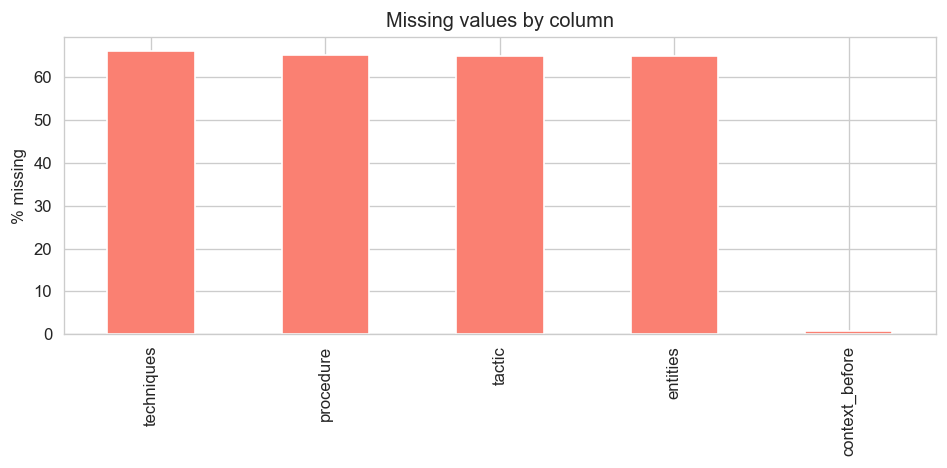

In [18]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

print(pd.DataFrame({"missing": missing, "pct": missing_pct}))

if (missing_pct > 0).any():
    plt.figure(figsize=(8, 4))
    missing_pct[missing_pct > 0].plot(kind="bar", color="salmon")
    plt.ylabel("% missing")
    plt.title("Missing values by column")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_missing_values.png")
    plt.show()


## 5. Class distribution


relevant
0    8002
1    4302
Name: count, dtype: int64

Proportions:
 relevant
0    0.6504
1    0.3496
Name: proportion, dtype: float64


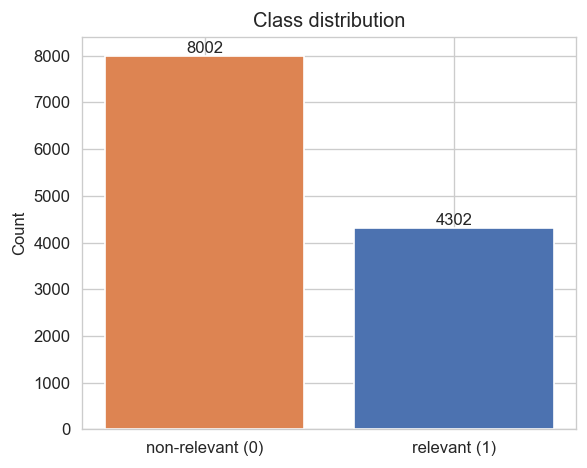

Imbalance ratio: 1.86:1


In [19]:
counts = df["relevant"].value_counts().sort_index()
print(counts)
print("\nProportions:\n",
      df["relevant"].value_counts(normalize=True).round(4))

vals = [counts.get(0, 0), counts.get(1, 0)]

plt.figure(figsize=(5, 4))
plt.bar(["non-relevant (0)", "relevant (1)"], vals,
        color=["#dd8452", "#4c72b0"])
for i, v in enumerate(vals):
    plt.text(i, v, str(v), ha="center", va="bottom")
plt.ylabel("Count")
plt.title("Class distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_class_distribution.png")
plt.show()

# --- Robust imbalance ratio ---
if counts.min() > 0 and len(counts) == 2:
    ratio = counts.max() / counts.min()
    print(f"Imbalance ratio: {ratio:.2f}:1")
elif len(counts) < 2:
    print("Imbalance ratio: undefined (only one class present)")
else:
    print("Imbalance ratio: undefined (a class is absent)")


## 6. Sentence-length distribution


        n_words   n_chars
count  12304.00  12304.00
mean      21.70    157.06
std       16.43    140.88
min        1.00      8.00
25%       12.00     86.00
50%       19.00    131.00
75%       27.00    187.00
max      366.00   2890.00


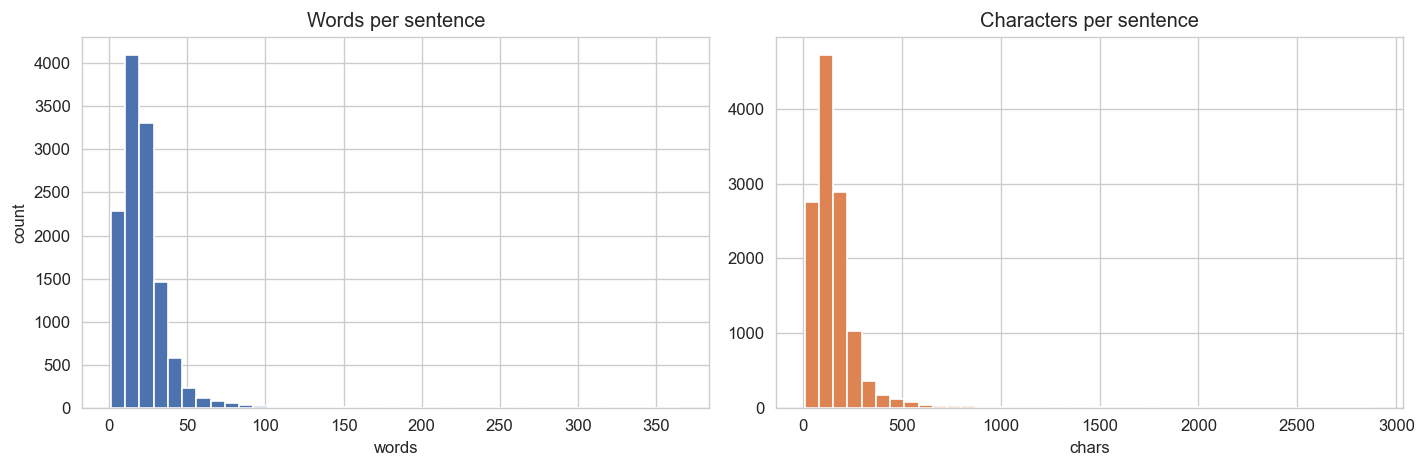

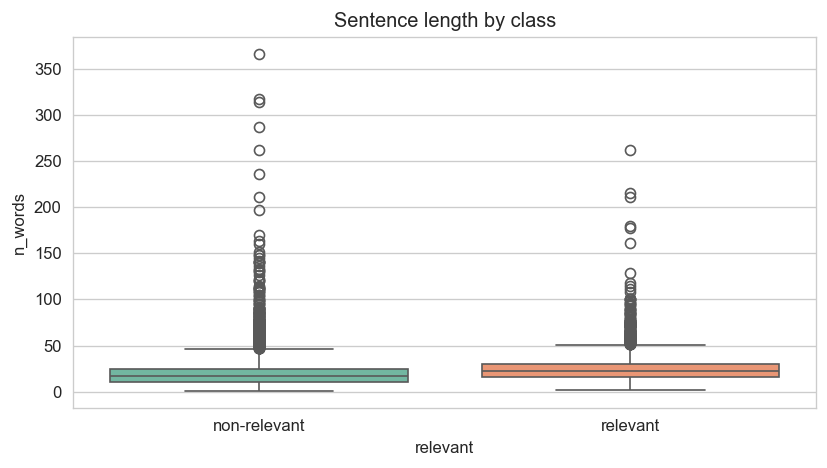

In [20]:
df["n_words"] = df["sentence_text"].astype(str).str.split().str.len()
df["n_chars"] = df["sentence_text"].astype(str).str.len()

print(df[["n_words", "n_chars"]].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["n_words"], bins=40, color="#4c72b0")
axes[0].set_title("Words per sentence")
axes[0].set_xlabel("words")
axes[0].set_ylabel("count")

axes[1].hist(df["n_chars"], bins=40, color="#dd8452")
axes[1].set_title("Characters per sentence")
axes[1].set_xlabel("chars")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_sentence_length.png")
plt.show()

if df["relevant"].nunique() == 2:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x="relevant", y="n_words", data=df,
                hue="relevant", palette="Set2", legend=False)
    plt.xticks([0, 1], ["non-relevant", "relevant"])
    plt.title("Sentence length by class")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_length_by_class.png")
    plt.show()
else:
    print("Only one class present — skipping boxplot.")


## 7. Document-level analysis


Documents: 100
count    100.00
mean     123.04
std      100.96
min        5.00
25%       55.00
50%      103.00
75%      159.00
max      521.00
dtype: float64


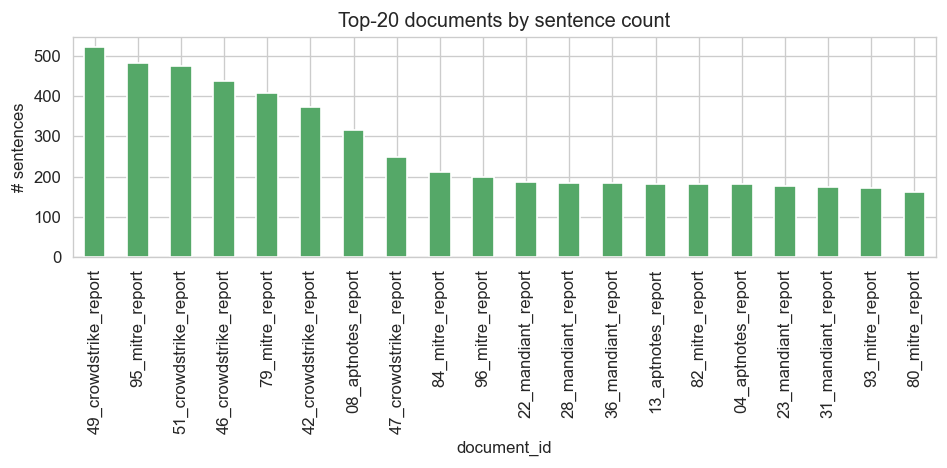

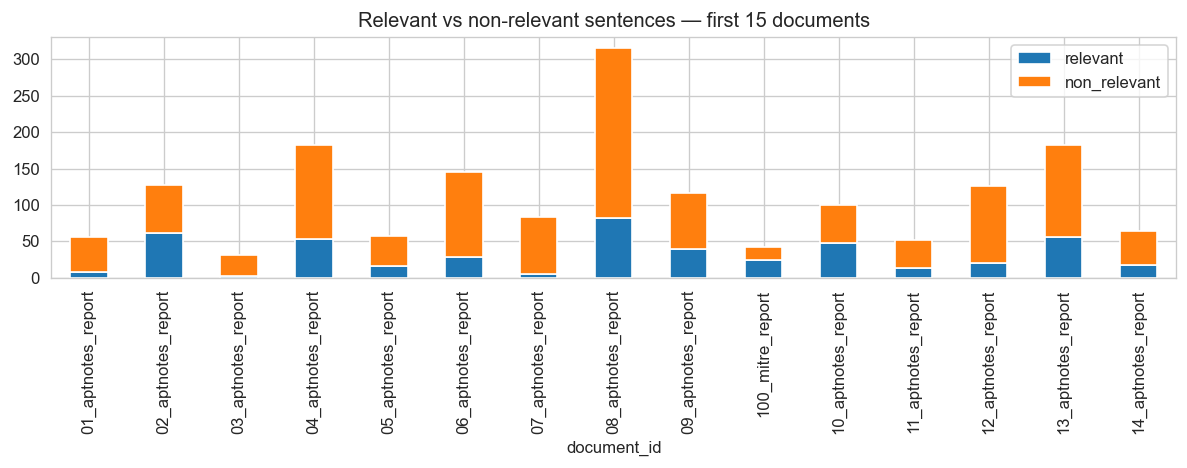

In [21]:
doc_counts = (
    df.groupby("document_id")
      .size()
      .sort_values(ascending=False)
)

print("Documents:", doc_counts.shape[0])
print(doc_counts.describe().round(2))

plt.figure(figsize=(8, 4))
doc_counts.head(20).plot(kind="bar", color="#55a868")
plt.title("Top-20 documents by sentence count")
plt.ylabel("# sentences")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_docs_top20.png")
plt.show()

per_doc = (
    df.groupby(["document_id", "relevant"])
      .size()
      .unstack(fill_value=0)
)
for col in (0, 1):
    if col not in per_doc.columns:
        per_doc[col] = 0
per_doc = per_doc[[1, 0]]
per_doc.columns = ["relevant", "non_relevant"]

per_doc.head(15).plot(kind="bar", stacked=True, figsize=(10, 4))
plt.title("Relevant vs non-relevant sentences — first 15 documents")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_per_doc_stacked.png")
plt.show()


## 8. Source analysis


source
mitre          3766
crowdstrike    2564
mandiant       2251
aptnotes       2106
sentinel       1617
Name: count, dtype: int64


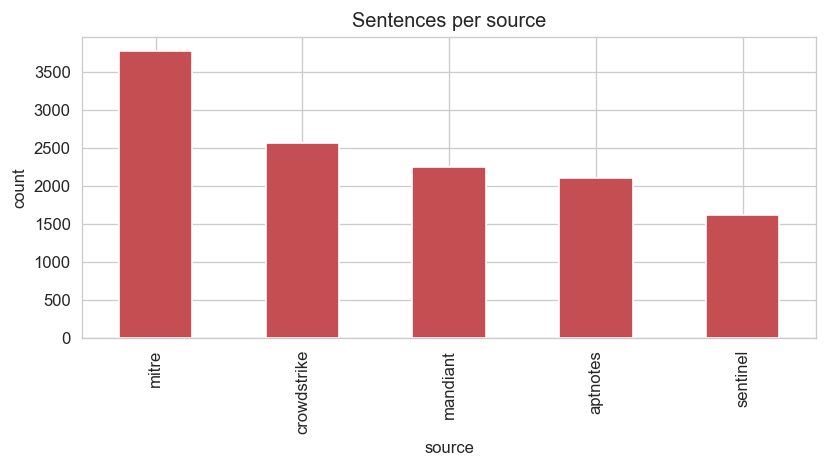

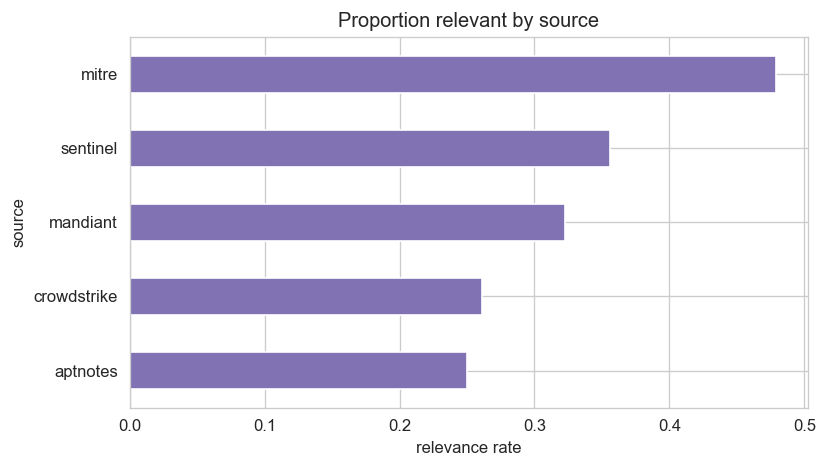

In [22]:
if "source" in df.columns:
    src = df["source"].value_counts()
    print(src)

    plt.figure(figsize=(7, 4))
    src.plot(kind="bar", color="#c44e52")
    plt.title("Sentences per source")
    plt.ylabel("count")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_sources.png")
    plt.show()

    rel_rate = (
        df.groupby("source")["relevant"].mean().sort_values()
    )
    plt.figure(figsize=(7, 4))
    rel_rate.plot(kind="barh", color="#8172b3")
    plt.xlabel("relevance rate")
    plt.title("Proportion relevant by source")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_relevance_by_source.png")
    plt.show()
else:
    print("No source column.")


## 9. Annotation coverage

`tactic`, `techniques`, `procedure` and `entities` are populated only for relevant
sentences. Placeholder strings such as `**`, `N/A`, `-` or `none` are treated as
missing **before** computing coverage, so the reported numbers reflect real
annotations.


In [23]:
ann_cols = ["tactic", "techniques", "procedure", "entities"]
present = [c for c in ann_cols if c in df.columns]

PLACEHOLDERS = {"**", "n/a", "na", "-", "none", "null", "", "nan"}

if present:
    # Replace known placeholders with NaN first
    ann_df = df[present].copy()
    for col in present:
        ann_df[col] = ann_df[col].apply(
            lambda v: np.nan
            if isinstance(v, str) and v.strip().lower() in PLACEHOLDERS
            else v
        )

    coverage = ann_df.notna().sum() / len(df) * 100
    print("Annotation coverage (%):\n", coverage.round(2))

    rel_mask = df["relevant"] == 1
    coverage_rel = (
        ann_df[rel_mask].notna().mean() * 100
    )
    print("\nCoverage among relevant only (%):\n",
          coverage_rel.round(2))

    # Any remaining suspiciously short values? Helpful for debugging.
    for col in present:
        vals = ann_df[col].dropna().astype(str).str.strip()
        short = vals[vals.str.len() <= 2].unique()[:10]
        if len(short):
            print(f"  Note: short '{col}' values (<=2 chars): {short}")


Annotation coverage (%):
 tactic        34.96
techniques    33.86
procedure     34.73
entities      34.96
dtype: float64

Coverage among relevant only (%):
 tactic        100.00
techniques     96.84
procedure      99.33
entities      100.00
dtype: float64
  Note: short 'techniques' values (<=2 chars): ['[]']


## 10. Top words per class


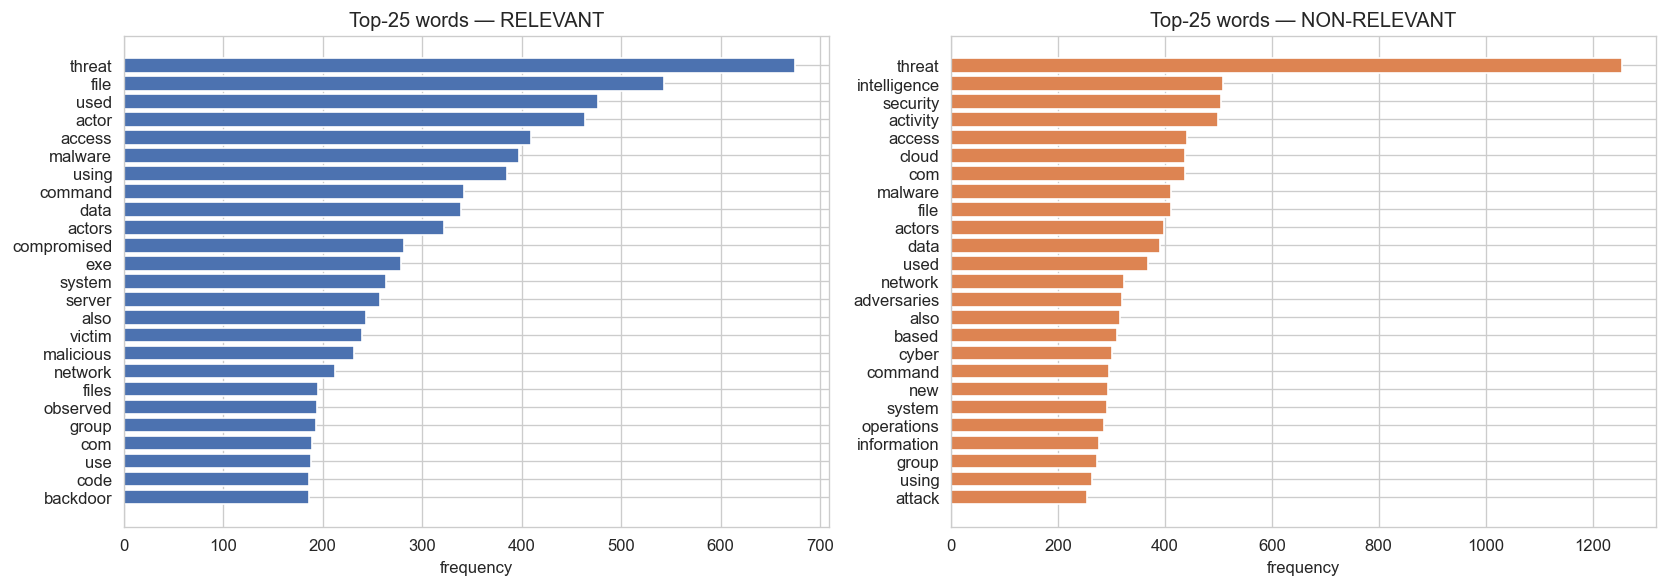

In [24]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
STOP = set(stopwords.words("english"))


def top_words(texts, n=25):
    tokens = []
    for t in texts:
        tokens += [
            w for w in re.findall(r"\b[a-z]{3,}\b", str(t).lower())
            if w not in STOP
        ]
    return Counter(tokens).most_common(n)


top_rel = top_words(df.loc[df["relevant"] == 1, "sentence_text"])
top_irrel = top_words(df.loc[df["relevant"] == 0, "sentence_text"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

panels = [
    (axes[0], top_rel, "Top-25 words — RELEVANT", "#4c72b0"),
    (axes[1], top_irrel, "Top-25 words — NON-RELEVANT", "#dd8452"),
]

for ax, data, title, color in panels:
    if not data:
        ax.set_title(f"{title} — no words available")
        ax.axis("off")
        continue
    words, counts_ = zip(*data)
    positions = range(len(words))[::-1]
    ax.barh(positions, counts_, color=color)
    ax.set_yticks(list(positions))
    ax.set_yticklabels(list(words))
    ax.set_title(title)
    ax.set_xlabel("frequency")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig_top_words.png")
plt.show()


## 11. Word clouds (optional)


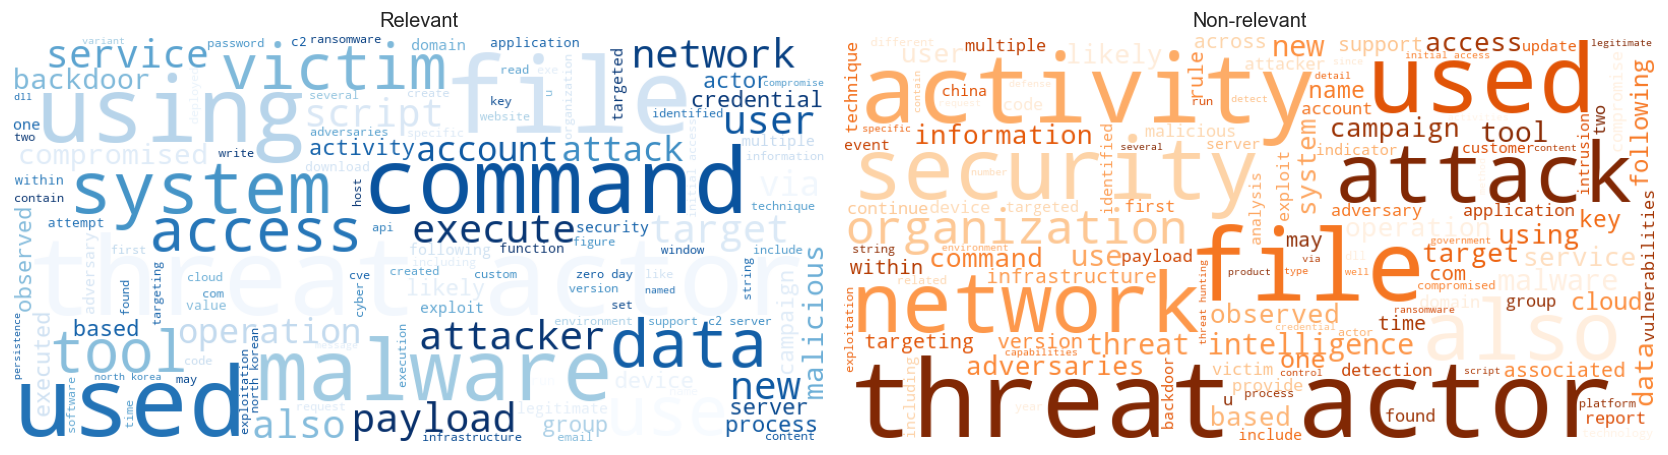

In [25]:
try:
    from wordcloud import WordCloud

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, sub, title, cmap in [
        (axes[0], df[df["relevant"] == 1], "Relevant", "Blues"),
        (axes[1], df[df["relevant"] == 0], "Non-relevant", "Oranges"),
    ]:
        text = " ".join(sub["sentence_text"].astype(str).str.lower())
        if not text.strip():
            ax.set_title(f"{title} — empty corpus")
            ax.axis("off")
            continue
        wc = WordCloud(
            width=800, height=400,
            background_color="white",
            colormap=cmap,
            stopwords=STOP,
            max_words=120,
        ).generate(text)
        ax.imshow(wc)
        ax.axis("off")
        ax.set_title(title)

    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_wordcloud.png")
    plt.show()
except ImportError:
    print("pip install wordcloud to enable word-cloud plot.")


## 12. Vocabulary statistics


In [26]:
all_tokens = re.findall(
    r"\b[a-z]{3,}\b",
    " ".join(df["sentence_text"].astype(str).str.lower()),
)
freq = Counter(all_tokens)
hapax = sum(1 for w, c in freq.items() if c == 1)
vocab = len(set(all_tokens))
total_tokens = len(all_tokens)

print("Total tokens:", total_tokens)
print("Unique tokens:", vocab)
if total_tokens:
    # NOTE: TTR is a corpus-level descriptive statistic and is not
    # directly comparable across corpora of different sizes.
    print("Type-token ratio (corpus-level):", round(vocab / total_tokens, 4))
    print(f"Hapax legomena: {hapax} ({hapax / vocab * 100:.1f}% of vocab)")
else:
    print("Corpus is empty — cannot compute vocabulary statistics.")


Total tokens: 221827
Unique tokens: 13292
Type-token ratio (corpus-level): 0.0599
Hapax legomena: 5003 (37.6% of vocab)


## 13. Save EDA summary


In [27]:
# --- Imbalance ratio handled consistently ---
if counts.min() > 0 and len(counts) == 2:
    imbalance_ratio = round(float(counts.max() / counts.min()), 3)
else:
    imbalance_ratio = None

eda = {
    "raw_rows": int(raw_rows),
    "rows_after_cleaning": int(len(df)),
    "rows_removed": int(raw_rows - len(df)),
    "relevant": int((df["relevant"] == 1).sum()),
    "non_relevant": int((df["relevant"] == 0).sum()),
    "imbalance_ratio": imbalance_ratio,
    "num_documents": int(df["document_id"].nunique()),
    "avg_words": round(float(df["n_words"].mean()), 2),
    "median_words": float(df["n_words"].median()),
    "max_words": int(df["n_words"].max()),
    "vocab_size": int(vocab),
    "type_token_ratio": (
        round(vocab / total_tokens, 4) if total_tokens else None
    ),
    "hapax_pct": round(hapax / vocab * 100, 2) if vocab else None,
    "num_sources": (
        int(df["source"].nunique()) if "source" in df.columns else None
    ),
}

summary_path = ARTIFACTS / "eda_summary.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(eda, f, indent=2)

print("Saved:", summary_path)
print(json.dumps(eda, indent=2))


Saved: d:\Projects\done\thesis\cti\artifacts\eda_summary.json
{
  "raw_rows": 12304,
  "rows_after_cleaning": 12304,
  "rows_removed": 0,
  "relevant": 4302,
  "non_relevant": 8002,
  "imbalance_ratio": 1.86,
  "num_documents": 100,
  "avg_words": 21.7,
  "median_words": 19.0,
  "max_words": 366,
  "vocab_size": 13292,
  "type_token_ratio": 0.0599,
  "hapax_pct": 37.64,
  "num_sources": 5
}


## 14. Research note

This notebook only **describes** the dataset. It does not establish that any
particular topic is an emerging threat. That claim requires separate evidence
from the BERTopic and temporal-analysis stages and must be discussed in the
corresponding chapters, not here.
